Name:Swaroop NaikRoll:23102A0001

#Mini Project: Image Recognition and Classification with Keras in R**Problem statement:** Build a deep learning pipeline in R that recognises handwritten digits(0-9) from 28x28 grayscale images. A fully connected (dense) neural network is trained first as abaseline, then a Convolutional Neural Network (CNN) is trained on the same data. The two models arecompared on test loss and accuracy, the better model is evaluated in detail with a confusion matrixand per-class precision / recall / F1, its mistakes are inspected visually, and finally the trainedmodel is used to recognise digits read back from external `.png` image files - the way a realrecognition system receives its input.**Dataset:** MNIST handwritten digits, bundled with Keras - 70,000 grayscale images of 28x28 pixels(60,000 for training, 10,000 for testing), each labelled with the digit it shows. Pixel intensitiesrange from 0 (black background) to 255 (white stroke).**Objectives**1. Load the MNIST image data in R and explore it (shapes, class balance, sample and mean images).2. Pre-process images: reshape, scale to [0, 1] and one-hot encode the labels.3. Train a baseline dense neural network and plot its learning curves.4. Train a CNN and show that convolution + pooling beats the dense baseline.5. Evaluate with a confusion matrix, per-class metrics and a gallery of misclassified digits.6. Recognise digits from external image files and save the trained model for reuse.**Tools:** R, `keras3` (TensorFlow backend), `caret`, `ggplot2`, `dplyr`, `tidyr`.**Reference:** *Image Recognition & Classification with Keras in R* - Dr. Bharatendra Rai(Deep Learning with R / Keras playlist), https://youtu.be/iExh0qj2Ouo

## 1. Setup`keras3` is the current R interface to Keras. It is a wrapper, so it needs a Python TensorFlowbackend behind it; `keras3::install_keras()` sets that up once per machine.

In [1]:
pkgs <- c("keras3", "caret", "ggplot2", "dplyr", "tidyr")
new  <- pkgs[!(pkgs %in% rownames(installed.packages()))]
if (length(new)) install.packages(new, repos = "https://cloud.r-project.org", quiet = TRUE)

suppressPackageStartupMessages({
  library(keras3); library(caret); library(ggplot2); library(dplyr); library(tidyr)
})

# One-time backend setup on a fresh machine (e.g. a new Colab runtime):
# run  keras3::install_keras(backend = "tensorflow")  once, then restart the session.

Sys.setenv(TF_CPP_MIN_LOG_LEVEL = "3")   # hide low-level TensorFlow logs
set_random_seed(42)                      # reproducible weight init and shuffling
options(repr.plot.width = 9, repr.plot.height = 5)

cat("keras3 version :", as.character(packageVersion("keras3")), "\n")
cat("Keras backend  :", as.character(config_backend()), "\n")

Warning message:
“Some Python package requirements declared via `py_require()` are not installed in the selected Python environment: (/tmp/claude-0/-home-user-23102A0001-R-Programming/30f6102b-b008-5d7f-ac18-7f91552f1bed/scratchpad/tfenv/bin/python)
  numpy pandas”


keras3 version : 1.5.1 


Keras backend  : tensorflow 


## 2. Loading and exploring the image data`dataset_mnist()` returns the data already split into train and test sets. The images arrive as a3-D array `(samples, height, width)` and the labels as a plain integer vector.

In [2]:
c(c(x_train, y_train), c(x_test, y_test)) %<-% dataset_mnist()

cat("Training images :", dim(x_train), "\n")
cat("Training labels :", length(y_train), "\n")
cat("Test images     :", dim(x_test),  "\n")
cat("Test labels     :", length(y_test), "\n")
cat("Pixel range     :", range(x_train), "\n")
cat("Label range     :", range(y_train), "\n")

Training images : 60000 28 28 


Training labels : 60000 


Test images     : 10000 28 28 


Test labels     : 10000 


Pixel range     : 0 255 


Label range     : 0 9 


In [3]:
# Is the dataset balanced across the ten digits?
dist <- data.frame(digit = 0:9,
                   train = as.integer(table(y_train)),
                   test  = as.integer(table(y_test)))
dist$train_pct <- round(100 * dist$train / sum(dist$train), 2)
dist

digit,train,test,train_pct
<int>,<int>,<int>,<dbl>
0,5923,980,9.87
1,6742,1135,11.24
2,5958,1032,9.93
3,6131,1010,10.22
4,5842,982,9.74
5,5421,892,9.04
6,5918,958,9.86
7,6265,1028,10.44
8,5851,974,9.75


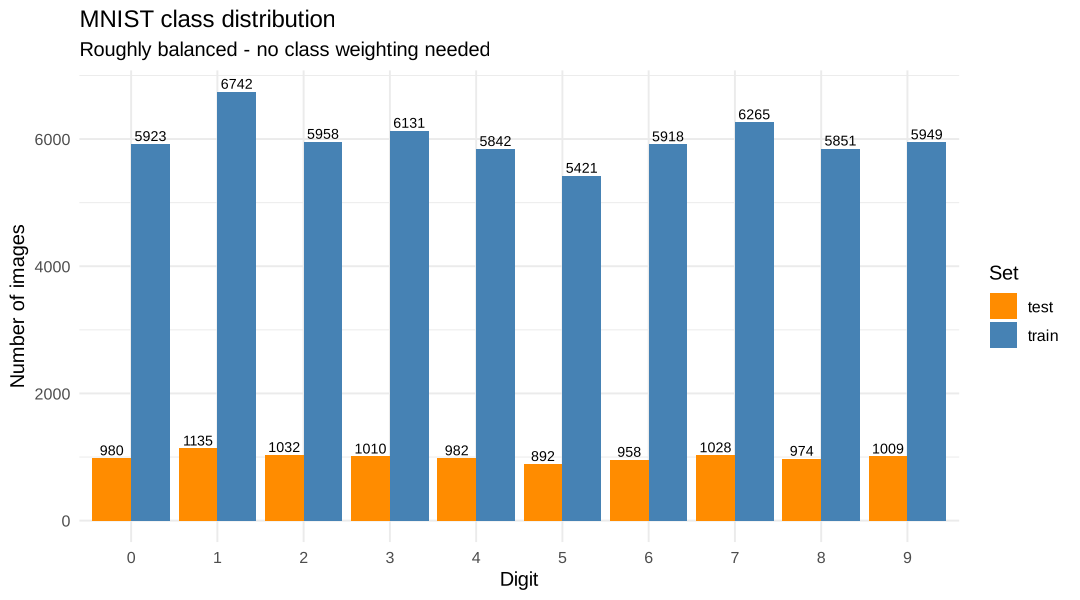

In [4]:
dist %>%
  pivot_longer(c(train, test), names_to = "set", values_to = "count") %>%
  ggplot(aes(x = factor(digit), y = count, fill = set)) +
  geom_col(position = "dodge") +
  geom_text(aes(label = count), position = position_dodge(0.9), vjust = -0.3, size = 3) +
  scale_fill_manual(values = c(train = "steelblue", test = "darkorange")) +
  labs(title = "MNIST class distribution", subtitle = "Roughly balanced - no class weighting needed",
       x = "Digit", y = "Number of images", fill = "Set") +
  theme_minimal(base_size = 12)

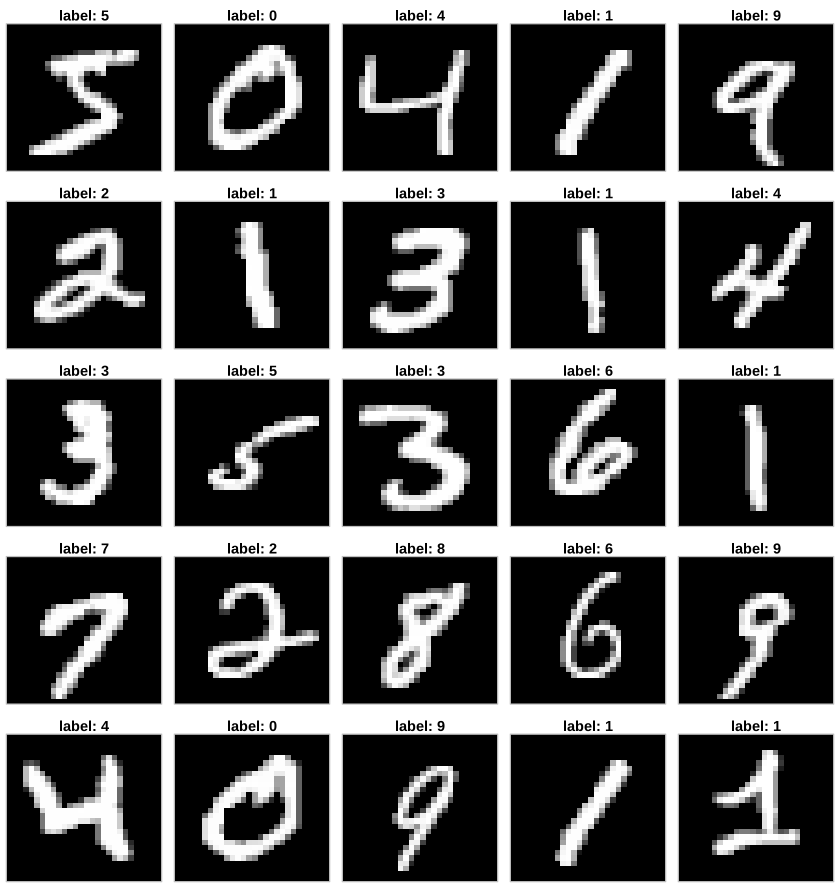

In [5]:
# Helper to draw one 28x28 matrix as an image.
# MNIST rows run top-to-bottom, so the rows are reversed and the matrix transposed
# before being handed to image(), which draws its y axis bottom-to-top.
show_digit <- function(mat, label = NULL) {
  image(1:28, 1:28, t(mat[28:1, ]),
        col = gray.colors(256, start = 0, end = 1),
        axes = FALSE, xlab = "", ylab = "", useRaster = TRUE)
  if (!is.null(label)) title(main = label, line = 0.2, cex.main = 1.1)
  box(col = "grey75")
}

options(repr.plot.width = 7, repr.plot.height = 7.4)
par(mfrow = c(5, 5), mar = c(0.4, 0.4, 1.5, 0.4))
for (i in 1:25) show_digit(x_train[i, , ], paste("label:", y_train[i]))

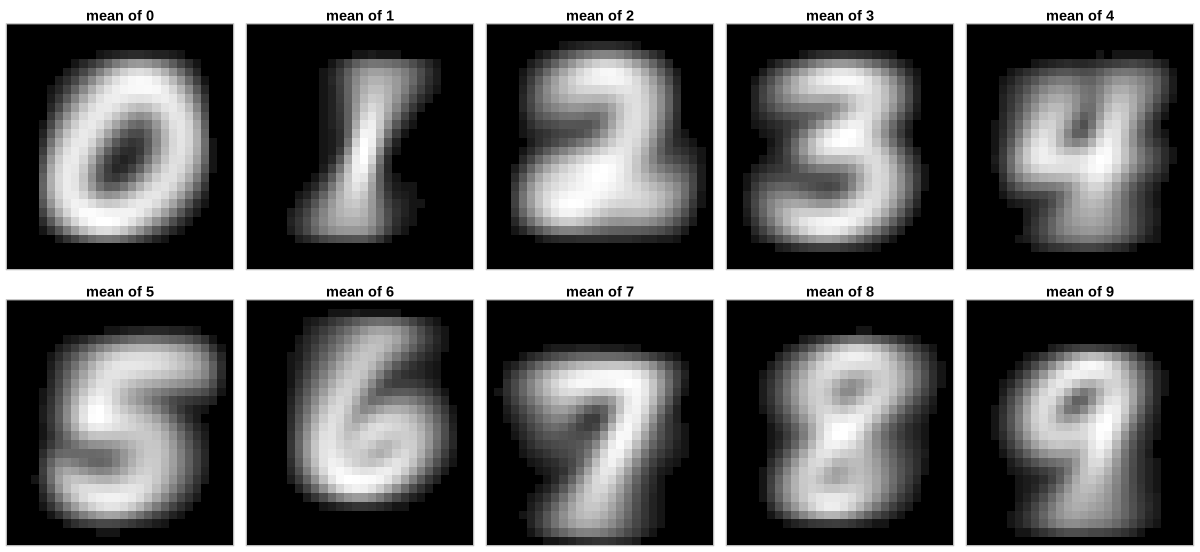

In [6]:
# The "average" digit of each class: where the ink usually falls.
# Sharp mean images (0, 1) are easy classes; blurry ones (5, 8) overlap with their neighbours.
options(repr.plot.width = 10, repr.plot.height = 4.6)
par(mfrow = c(2, 5), mar = c(0.4, 0.4, 1.5, 0.4))
for (d in 0:9) {
  avg <- apply(x_train[y_train == d, , ], c(2, 3), mean)
  show_digit(avg, paste("mean of", d))
}

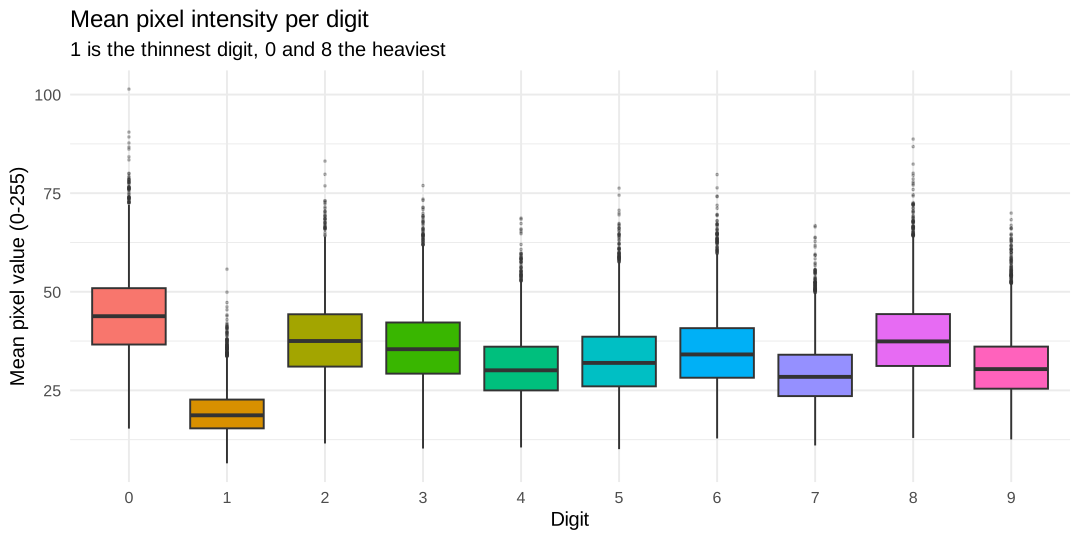

In [7]:
# How much ink does each digit carry? A simple numeric feature per class.
ink <- data.frame(digit = factor(y_train), intensity = apply(x_train, 1, mean))

options(repr.plot.width = 9, repr.plot.height = 4.5)
ggplot(ink, aes(x = digit, y = intensity, fill = digit)) +
  geom_boxplot(show.legend = FALSE, outlier.size = 0.4, outlier.alpha = 0.3) +
  labs(title = "Mean pixel intensity per digit",
       subtitle = "1 is the thinnest digit, 0 and 8 the heaviest",
       x = "Digit", y = "Mean pixel value (0-255)") +
  theme_minimal(base_size = 12)

## 3. Pre-processingThree things have to happen before training:1. **Reshape.** A dense layer needs a flat vector of 784 values per image; a convolution layer needs   the spatial layout kept intact, as `(28, 28, 1)` - height, width and one colour channel.2. **Scale.** Pixels are divided by 255 so every input lies in `[0, 1]`, which keeps the gradients   well behaved.3. **One-hot encode.** The label `7` becomes the vector `(0,0,0,0,0,0,0,1,0,0)` so it can be compared   against the 10 softmax outputs with categorical cross-entropy.

In [8]:
# Flattened and scaled - input for the dense network
x_train_flat <- array_reshape(x_train, c(nrow(x_train), 784)) / 255
x_test_flat  <- array_reshape(x_test,  c(nrow(x_test),  784)) / 255

# 4-D (samples, height, width, channels) and scaled - input for the CNN
x_train_img <- array_reshape(x_train, c(nrow(x_train), 28, 28, 1)) / 255
x_test_img  <- array_reshape(x_test,  c(nrow(x_test),  28, 28, 1)) / 255

# One-hot encoded targets for both models
y_train_oh <- to_categorical(y_train, num_classes = 10)
y_test_oh  <- to_categorical(y_test,  num_classes = 10)

cat("x_train_flat :", dim(x_train_flat), "\n")
cat("x_train_img  :", dim(x_train_img),  "\n")
cat("y_train_oh   :", dim(y_train_oh),   "\n")
cat("Scaled pixel range:", range(x_train_flat), "\n\n")
cat("First 3 labels:", y_train[1:3], "-> one-hot:\n")
y_train_oh[1:3, ]

x_train_flat : 60000 784 


x_train_img  : 60000 28 28 1 


y_train_oh   : 60000 10 


Scaled pixel range: 0 1 



First 3 labels: 5 0 4 -> one-hot:


0,0,0,0,0,1,0,0,0,0
1,0,0,0,0,0,0,0,0,0
0,0,0,0,1,0,0,0,0,0


## 4. Model A - baseline dense neural networkTwo hidden ReLU layers with dropout between them, and a 10-unit softmax output. Flattening the imagethrows away the fact that neighbouring pixels belong together, which is exactly the weakness the CNNin section 5 fixes.

In [9]:
dnn <- keras_model_sequential(input_shape = c(784), name = "dense_baseline") %>%
  layer_dense(units = 512, activation = "relu") %>%
  layer_dropout(rate = 0.3) %>%
  layer_dense(units = 256, activation = "relu") %>%
  layer_dropout(rate = 0.3) %>%
  layer_dense(units = 10, activation = "softmax")

summary(dnn)

Model: "dense_baseline"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                      ┃ Output Shape             ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                     │ (None, 512)              │       401,920 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dropout (Dropout)                 │ (None, 512)              │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense_1 (Dense)                   │ (None, 256)              │       131,328 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dropout_1 (Dropout)               │ (None, 256)              │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense_2 (Dense)                   │ (None, 10)               │         2,570 │
└───

In [10]:
dnn %>% compile(
  loss      = "categorical_crossentropy",
  optimizer = optimizer_adam(learning_rate = 1e-3),
  metrics   = "accuracy"
)

# Keras prints its progress to Python's stdout, which the R kernel does not pick up on its
# own, so py_capture_output() pulls the training log back into the notebook.
train_log_dnn <- reticulate::py_capture_output({
  hist_dnn <- dnn %>% fit(
    x_train_flat, y_train_oh,
    epochs           = 15,
    batch_size       = 128,
    validation_split = 0.2,   # 48,000 images to train on, 12,000 to validate
    verbose          = 2
  )
})
cat(train_log_dnn)

Epoch 1/15
375/375 - 3s - 8ms/step - accuracy: 0.9033 - loss: 0.3229 - val_accuracy: 0.9597 - val_loss: 0.1271
Epoch 2/15
375/375 - 2s - 6ms/step - accuracy: 0.9596 - loss: 0.1356 - val_accuracy: 0.9678 - val_loss: 0.1014
Epoch 3/15
375/375 - 2s - 6ms/step - accuracy: 0.9700 - loss: 0.0962 - val_accuracy: 0.9749 - val_loss: 0.0856
Epoch 4/15
375/375 - 2s - 6ms/step - accuracy: 0.9768 - loss: 0.0771 - val_accuracy: 0.9765 - val_loss: 0.0803
Epoch 5/15
375/375 - 2s - 6ms/step - accuracy: 0.9794 - loss: 0.0653 - val_accuracy: 0.9773 - val_loss: 0.0797
Epoch 6/15
375/375 - 2s - 6ms/step - accuracy: 0.9822 - loss: 0.0561 - val_accuracy: 0.9775 - val_loss: 0.0784
Epoch 7/15
375/375 - 2s - 6ms/step - accuracy: 0.9842 - loss: 0.0490 - val_accuracy: 0.9784 - val_loss: 0.0788
Epoch 8/15
375/375 - 2s - 6ms/step - accuracy: 0.9858 - loss: 0.0423 - val_accuracy: 0.9797 - val_loss: 0.0738
Epoch 9/15
375/375 - 2s - 6ms/step - accuracy: 0.9871 - loss: 0.0395 - val_accuracy: 0.9787 - val_loss: 0.0825
E

In [11]:
# The same numbers as a tidy per-epoch table
hist_table <- function(h) {
  m <- h$metrics
  data.frame(epoch        = seq_along(m$loss),
             loss         = round(m$loss, 4),
             accuracy     = round(m$accuracy, 4),
             val_loss     = round(m$val_loss, 4),
             val_accuracy = round(m$val_accuracy, 4))
}
hist_table(hist_dnn)

epoch,loss,accuracy,val_loss,val_accuracy
<int>,<dbl>,<dbl>,<dbl>,<dbl>
1,0.3229,0.9033,0.1271,0.9597
2,0.1356,0.9596,0.1014,0.9678
3,0.0962,0.9700,0.0856,0.9749
4,0.0771,0.9768,0.0803,0.9765
5,0.0653,0.9794,0.0797,0.9773
6,0.0561,0.9822,0.0784,0.9775
7,0.0490,0.9842,0.0788,0.9784
8,0.0423,0.9858,0.0738,0.9797
9,0.0395,0.9871,0.0825,0.9787


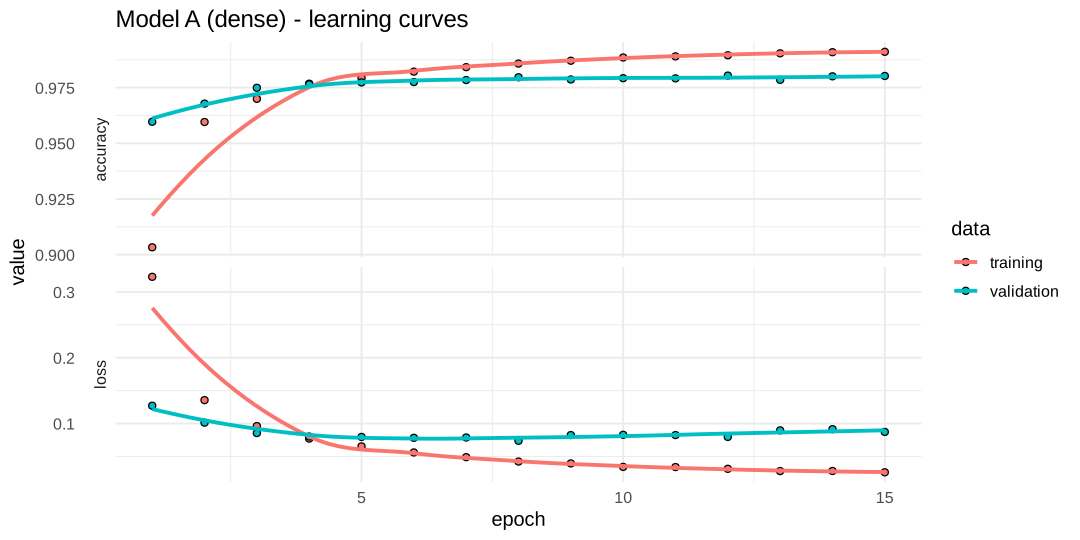

In [12]:
options(repr.plot.width = 9, repr.plot.height = 4.5)
plot(hist_dnn) + labs(title = "Model A (dense) - learning curves") + theme_minimal(base_size = 12)

In [13]:
eval_dnn <- dnn %>% evaluate(x_test_flat, y_test_oh, verbose = 0)
cat("Model A - dense neural network\n")
cat("Test loss     :", round(eval_dnn$loss, 4), "\n")
cat("Test accuracy :", round(eval_dnn$accuracy, 4),
    sprintf("(%.2f%%)", 100 * eval_dnn$accuracy), "\n")

Model A - dense neural network


Test loss     : 0.0728 


Test accuracy : 0.981 (98.10%) 


## 5. Model B - Convolutional Neural NetworkA CNN slides small learnable filters over the image, so it picks up strokes, edges and curves whereverthey appear instead of memorising pixel positions:- two `conv_2d` layers (32 then 64 filters, 3x3) to extract local features,- `max_pooling_2d` to halve the spatial size and add translation tolerance,- `dropout` twice to curb overfitting,- `flatten` then a 128-unit dense layer before the softmax output.

In [14]:
cnn <- keras_model_sequential(input_shape = c(28, 28, 1), name = "mnist_cnn") %>%
  layer_conv_2d(filters = 32, kernel_size = c(3, 3), activation = "relu") %>%
  layer_conv_2d(filters = 64, kernel_size = c(3, 3), activation = "relu") %>%
  layer_max_pooling_2d(pool_size = c(2, 2)) %>%
  layer_dropout(rate = 0.25) %>%
  layer_flatten() %>%
  layer_dense(units = 128, activation = "relu") %>%
  layer_dropout(rate = 0.5) %>%
  layer_dense(units = 10, activation = "softmax")

summary(cnn)

Model: "mnist_cnn"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                      ┃ Output Shape             ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                   │ (None, 26, 26, 32)       │           320 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)                 │ (None, 24, 24, 64)       │        18,496 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)      │ (None, 12, 12, 64)       │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dropout_2 (Dropout)               │ (None, 12, 12, 64)       │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ flatten (Flatten)                 │ (None, 9216)             │             0 │
├────────

In [15]:
cnn %>% compile(
  loss      = "categorical_crossentropy",
  optimizer = optimizer_adam(learning_rate = 1e-3),
  metrics   = "accuracy"
)

train_log_cnn <- reticulate::py_capture_output({
  hist_cnn <- cnn %>% fit(
    x_train_img, y_train_oh,
    epochs           = 10,
    batch_size       = 128,
    validation_split = 0.2,
    verbose          = 2
  )
})
cat(train_log_cnn)

Epoch 1/10
375/375 - 14s - 38ms/step - accuracy: 0.9138 - loss: 0.2798 - val_accuracy: 0.9798 - val_loss: 0.0652
Epoch 2/10
375/375 - 13s - 35ms/step - accuracy: 0.9690 - loss: 0.1029 - val_accuracy: 0.9859 - val_loss: 0.0496
Epoch 3/10
375/375 - 14s - 36ms/step - accuracy: 0.9768 - loss: 0.0751 - val_accuracy: 0.9867 - val_loss: 0.0470
Epoch 4/10
375/375 - 13s - 36ms/step - accuracy: 0.9822 - loss: 0.0587 - val_accuracy: 0.9881 - val_loss: 0.0393
Epoch 5/10
375/375 - 13s - 35ms/step - accuracy: 0.9839 - loss: 0.0510 - val_accuracy: 0.9894 - val_loss: 0.0385
Epoch 6/10
375/375 - 21s - 55ms/step - accuracy: 0.9861 - loss: 0.0436 - val_accuracy: 0.9899 - val_loss: 0.0352
Epoch 7/10
375/375 - 13s - 35ms/step - accuracy: 0.9877 - loss: 0.0378 - val_accuracy: 0.9896 - val_loss: 0.0366
Epoch 8/10
375/375 - 13s - 34ms/step - accuracy: 0.9891 - loss: 0.0347 - val_accuracy: 0.9899 - val_loss: 0.0386
Epoch 9/10
375/375 - 13s - 34ms/step - accuracy: 0.9891 - loss: 0.0320 - val_accuracy: 0.9893 - 

In [16]:
hist_table(hist_cnn)

epoch,loss,accuracy,val_loss,val_accuracy
<int>,<dbl>,<dbl>,<dbl>,<dbl>
1,0.2798,0.9138,0.0652,0.9798
2,0.1029,0.9690,0.0496,0.9859
3,0.0751,0.9768,0.0470,0.9867
4,0.0587,0.9822,0.0393,0.9881
5,0.0510,0.9839,0.0385,0.9894
6,0.0436,0.9861,0.0352,0.9899
7,0.0378,0.9877,0.0366,0.9896
8,0.0347,0.9891,0.0386,0.9899
9,0.0320,0.9891,0.0413,0.9893


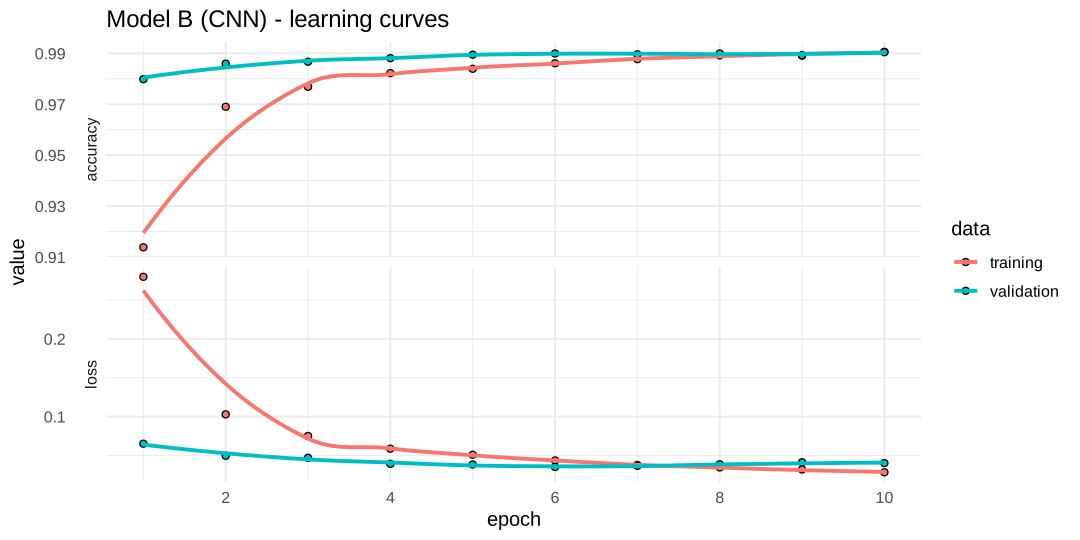

In [17]:
options(repr.plot.width = 9, repr.plot.height = 4.5)
plot(hist_cnn) + labs(title = "Model B (CNN) - learning curves") + theme_minimal(base_size = 12)

In [18]:
eval_cnn <- cnn %>% evaluate(x_test_img, y_test_oh, verbose = 0)
cat("Model B - convolutional neural network\n")
cat("Test loss     :", round(eval_cnn$loss, 4), "\n")
cat("Test accuracy :", round(eval_cnn$accuracy, 4),
    sprintf("(%.2f%%)", 100 * eval_cnn$accuracy), "\n")

Model B - convolutional neural network


Test loss     : 0.0305 


Test accuracy : 0.9921 (99.21%) 


## 6. Comparing the two models

In [19]:
results <- data.frame(
  Model         = c("A: Dense 784-512-256-10", "B: CNN 32/64 conv + dense 128"),
  Parameters    = c(dnn$count_params(), cnn$count_params()),
  Test_loss     = round(c(eval_dnn$loss, eval_cnn$loss), 4),
  Test_accuracy = round(c(eval_dnn$accuracy, eval_cnn$accuracy), 4),
  Test_error_pct = round(100 * (1 - c(eval_dnn$accuracy, eval_cnn$accuracy)), 2)
)
results

Model,Parameters,Test_loss,Test_accuracy,Test_error_pct
<chr>,<int>,<dbl>,<dbl>,<dbl>
A: Dense 784-512-256-10,535818,0.0728,0.9810,1.90
B: CNN 32/64 conv + dense 128,1199882,0.0305,0.9921,0.79


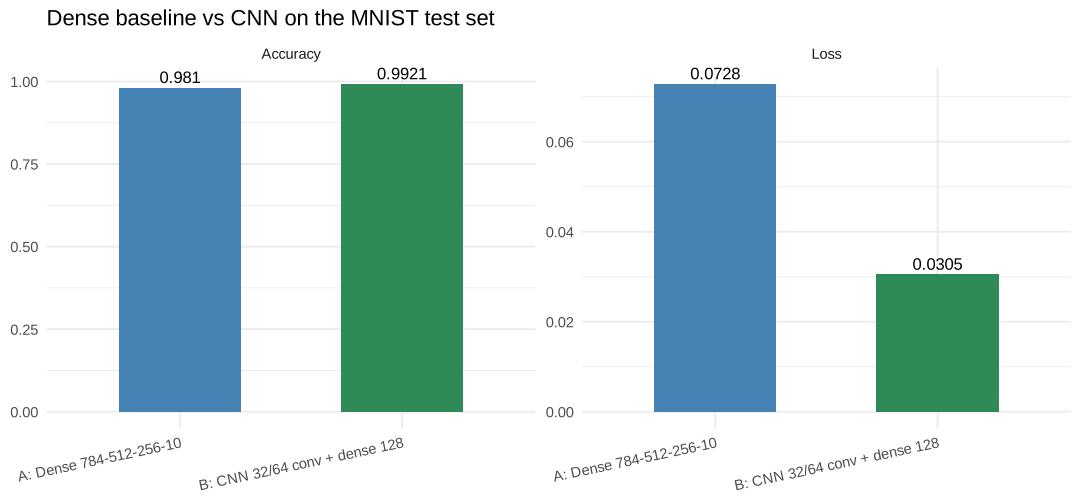

In [20]:
options(repr.plot.width = 9, repr.plot.height = 4.2)
results %>%
  select(Model, Accuracy = Test_accuracy, Loss = Test_loss) %>%
  pivot_longer(-Model, names_to = "metric", values_to = "value") %>%
  ggplot(aes(x = Model, y = value, fill = Model)) +
  geom_col(width = 0.55, show.legend = FALSE) +
  geom_text(aes(label = round(value, 4)), vjust = -0.4, size = 3.5) +
  facet_wrap(~ metric, scales = "free_y") +
  scale_fill_manual(values = c("steelblue", "seagreen")) +
  labs(title = "Dense baseline vs CNN on the MNIST test set", x = NULL, y = NULL) +
  theme_minimal(base_size = 11) +
  theme(axis.text.x = element_text(angle = 12, hjust = 1))

## 7. Detailed evaluation of the better model`predict()` returns a 10,000 x 10 matrix of class probabilities. Taking `which.max` of each row (andsubtracting 1, because R indexes from 1 while the digits start at 0) gives the predicted label.

In [21]:
prob_cnn <- predict(cnn, x_test_img, verbose = 0)
pred_cnn <- apply(prob_cnn, 1, which.max) - 1

cat("Probability matrix:", dim(prob_cnn), "\n\n")
cat("Example - test image 1 (true label", y_test[1], "):\n")
round(setNames(prob_cnn[1, ], 0:9), 5)

Probability matrix: 10000 10 



Example - test image 1 (true label 7 ):


0 1 2 3 4 5 6 7 8 9 
0 0 0 0 0 0 0 1 0 0

In [22]:
cm <- confusionMatrix(factor(pred_cnn, levels = 0:9), factor(y_test, levels = 0:9))
cm$table

          Reference
Prediction    0    1    2    3    4    5    6    7    8    9
         0  977    0    1    0    0    1    4    0    1    3
         1    0 1132    0    0    0    0    2    0    0    1
         2    0    2 1023    1    0    0    0    5    2    1
         3    0    1    0 1006    0    5    0    0    0    1
         4    0    0    0    0  978    0    1    0    0    7
         5    0    0    0    2    0  884    2    0    0    5
         6    1    0    0    0    1    1  947    0    0    0
         7    1    0    8    0    0    0    0 1022    3    5
         8    1    0    0    1    1    1    2    1  967    1
         9    0    0    0    0    2    0    0    0    1  985

In [23]:
cat("Overall statistics\n")
round(cm$overall[c("Accuracy", "Kappa", "AccuracyLower", "AccuracyUpper")], 4)

Overall statistics


Accuracy         Kappa AccuracyLower AccuracyUpper 
       0.9921        0.9912        0.9902        0.9937

In [24]:
per_class <- as.data.frame(cm$byClass[, c("Sensitivity", "Specificity", "Precision", "F1")])
per_class <- cbind(Digit = 0:9, round(per_class, 4))
rownames(per_class) <- NULL
per_class

Digit,Sensitivity,Specificity,Precision,F1
<int>,<dbl>,<dbl>,<dbl>,<dbl>
0,0.9969,0.9989,0.9899,0.9934
1,0.9974,0.9997,0.9974,0.9974
2,0.9913,0.9988,0.9894,0.9903
3,0.9960,0.9992,0.9931,0.9946
4,0.9959,0.9991,0.9919,0.9939
5,0.9910,0.9990,0.9899,0.9905
6,0.9885,0.9997,0.9968,0.9927
7,0.9942,0.9981,0.9836,0.9889
8,0.9928,0.9991,0.9918,0.9923


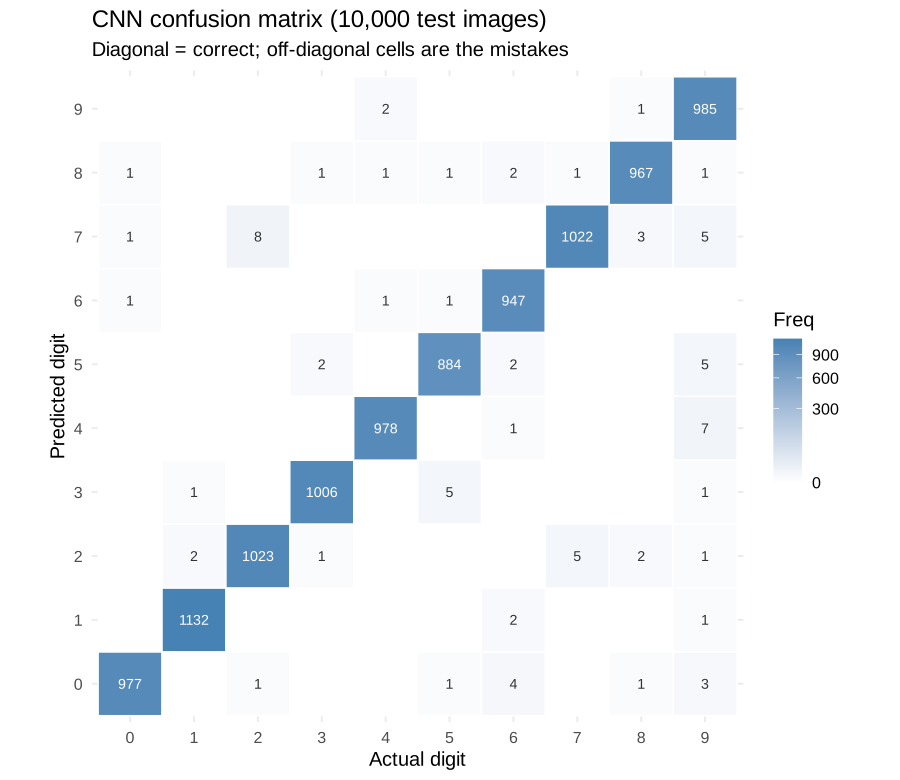

In [25]:
cm_df <- as.data.frame(cm$table)
names(cm_df) <- c("Predicted", "Actual", "Freq")

options(repr.plot.width = 7.5, repr.plot.height = 6.5)
ggplot(cm_df, aes(x = Actual, y = Predicted, fill = Freq)) +
  geom_tile(colour = "white", linewidth = 0.4) +
  geom_text(aes(label = ifelse(Freq > 0, Freq, "")),
            size = 3, colour = ifelse(cm_df$Freq > 400, "white", "grey20")) +
  scale_fill_gradient(low = "white", high = "steelblue", trans = "sqrt") +
  labs(title = "CNN confusion matrix (10,000 test images)",
       subtitle = "Diagonal = correct; off-diagonal cells are the mistakes",
       x = "Actual digit", y = "Predicted digit") +
  coord_fixed() +
  theme_minimal(base_size = 12)

In [26]:
# Which digit pairs does the model confuse most often?
off <- cm$table
diag(off) <- 0
confused <- as.data.frame(off)
names(confused) <- c("Predicted", "Actual", "Count")
confused %>% filter(Count > 0) %>% arrange(desc(Count)) %>% head(10)

,Predicted,Actual,Count
,<fct>,<fct>,<dbl>
1,7,2,8
2,4,9,7
3,3,5,5
4,2,7,5
5,5,9,5
6,7,9,5
7,0,6,4
8,7,8,3
9,0,9,3


Misclassified: 79 of 10000 (0.79%)


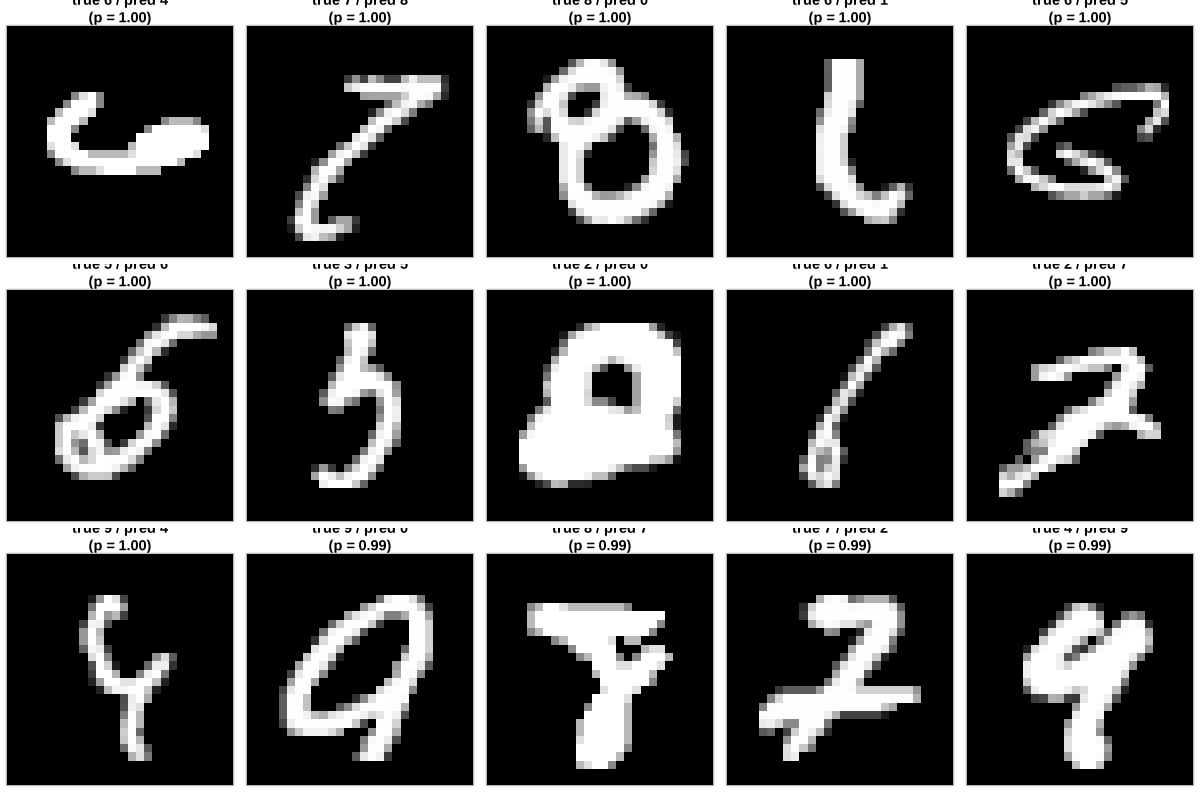

In [27]:
wrong <- which(pred_cnn != y_test)
cat("Misclassified:", length(wrong), "of", length(y_test),
    sprintf("(%.2f%%)\n", 100 * length(wrong) / length(y_test)))

# The mistakes the model was most confident about - usually genuinely ambiguous handwriting
conf  <- apply(prob_cnn[wrong, , drop = FALSE], 1, max)
worst <- wrong[order(conf, decreasing = TRUE)][1:15]

options(repr.plot.width = 10, repr.plot.height = 6.6)
par(mfrow = c(3, 5), mar = c(0.4, 0.4, 1.6, 0.4))
for (i in worst) {
  show_digit(x_test[i, , ],
             sprintf("true %d / pred %d\n(p = %.2f)", y_test[i], pred_cnn[i], max(prob_cnn[i, ])))
}

## 8. Recognising digits from external image filesSo far the model has only seen arrays that were already in memory. A real recognition system is handedan image *file*. Here a few test digits are written out as `.png` files and then read back from diskwith `image_load()` / `image_to_array()` - the same route any new scanned or photographed digit wouldtake.

In [28]:
dir.create("sample_digits", showWarnings = FALSE)

idx     <- c(4, 16, 47, 102, 211)
samples <- data.frame(path = character(0), true_label = integer(0))
for (i in idx) {
  p <- file.path("sample_digits", sprintf("digit_%03d_true%d.png", i, y_test[i]))
  image_array_save(array_reshape(x_test[i, , ], c(28, 28, 1)), p, scale = FALSE)
  samples <- rbind(samples, data.frame(path = p, true_label = y_test[i]))
}
samples

path,true_label
<chr>,<int>
sample_digits/digit_004_true0.png,0
sample_digits/digit_016_true5.png,5
sample_digits/digit_047_true1.png,1
sample_digits/digit_102_true0.png,0
sample_digits/digit_211_true4.png,4


In [29]:
# Read an image file back from disk and classify it
classify_image <- function(path, truth) {
  img <- image_load(path, color_mode = "grayscale", target_size = c(28, 28))
  arr <- image_to_array(img) / 255             # (28, 28, 1), scaled to [0, 1]
  arr <- array_reshape(arr, c(1, 28, 28, 1))   # add the batch dimension
  pr  <- predict(cnn, arr, verbose = 0)[1, ]
  ord <- order(pr, decreasing = TRUE)
  data.frame(file         = basename(path),
             true_label   = truth,
             prediction   = ord[1] - 1,
             correct      = (ord[1] - 1) == truth,
             confidence   = sprintf("%.6f", pr[ord[1]]),
             second_guess = ord[2] - 1,
             second_prob  = formatC(pr[ord[2]], format = "e", digits = 2))
}

recognised <- do.call(rbind, Map(classify_image, samples$path, samples$true_label))
rownames(recognised) <- NULL
recognised

cat("Read back from disk and recognised correctly:",
    sum(recognised$correct), "of", nrow(recognised), "\n")

file,true_label,prediction,correct,confidence,second_guess,second_prob
<chr>,<int>,<dbl>,<lgl>,<chr>,<dbl>,<chr>
digit_004_true0.png,0,0,TRUE,1.000000,6,2.41e-08
digit_016_true5.png,5,5,TRUE,1.000000,3,3.39e-08
digit_047_true1.png,1,1,TRUE,1.000000,3,2.68e-07
digit_102_true0.png,0,0,TRUE,1.000000,6,1.32e-09
digit_211_true4.png,4,4,TRUE,1.000000,9,6.18e-10


Read back from disk and recognised correctly: 5 of 5 


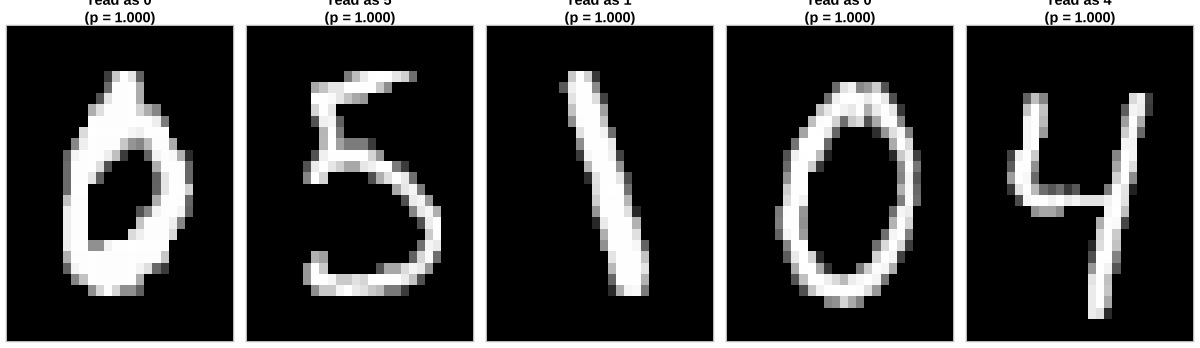

In [30]:
# Show each file next to what the model read it as
options(repr.plot.width = 10, repr.plot.height = 2.9)
par(mfrow = c(1, 5), mar = c(0.4, 0.4, 1.6, 0.4))
for (k in seq_len(nrow(samples))) {
  arr <- image_to_array(image_load(samples$path[k], color_mode = "grayscale",
                                   target_size = c(28, 28)))
  show_digit(arr[, , 1], sprintf("read as %d\n(p = %.3f)",
                                 recognised$prediction[k],
                                 as.numeric(recognised$confidence[k])))
}

## 9. Saving the trained modelThe `.keras` file holds the architecture, the trained weights and the optimiser state, so the model canbe reloaded later without retraining.

In [31]:
save_model(cnn, "mnist_cnn.keras", overwrite = TRUE)
cat("Saved:", file.exists("mnist_cnn.keras"),
    sprintf("(%.1f MB)\n", file.size("mnist_cnn.keras") / 1024^2))

reloaded <- load_model("mnist_cnn.keras")
re_eval  <- reloaded %>% evaluate(x_test_img, y_test_oh, verbose = 0)
cat("Reloaded model test accuracy:", round(re_eval$accuracy, 4),
    "- matches the original:", isTRUE(all.equal(re_eval$accuracy, eval_cnn$accuracy)), "\n")

Saved: TRUE (13.8 MB)


Reloaded model test accuracy: 0.9921 - matches the original: TRUE 


## 10. Conclusion

**Final results on the 10,000-image test set**

| Model | Parameters | Test loss | Test accuracy | Test error |
|---|---|---|---|---|
| A: Dense 784-512-256-10 | 535,818 | 0.0728 | **98.10%** | 1.90% |
| B: CNN 32/64 conv + dense 128 | 1,199,882 | 0.0305 | **99.21%** | 0.79% |

CNN accuracy 0.9921, Kappa 0.9912, 95% CI [0.9902, 0.9937] - 79 wrong out of 10,000.

**Observations**

1. **Convolution is what matters, not size.** The CNN cut the error rate from 1.90% to 0.79% - a
   58% reduction - and needed 10 epochs instead of 15. Flattening an image to 784 numbers destroys
   the information that neighbouring pixels belong together; convolution filters keep it and learn
   strokes and curves that work wherever they appear in the frame.
2. **The dense model overfits, the CNN does not.** Model A's training accuracy climbed to 99.11%
   while its validation accuracy stalled at 98.03%, and validation loss turned upward after epoch 8
   (0.0738 -> 0.0873) - it was memorising. Model B finished at 99.06% training vs 99.04% validation,
   so the two curves stayed together and the gap never opened.
3. **The hardest digit is 9** (sensitivity 0.9762): 7 nines were read as 4, 5 as 5 and 3 as 0. The
   easiest is **1** (F1 0.9974), which is unsurprising - its mean image in section 2 is the sharpest
   of the ten, while 5, 8 and 9 are the blurriest, i.e. the most variable in how people write them.
4. **Mistakes follow shape, not chance.** The top confusions are 2->7 (8 cases), 9->4 (7), 5->3 and
   7->2 (5 each) - every one a pair that shares most of its strokes. No digit pair is confused
   because of class imbalance; the dataset is near-balanced (9.0%-11.2% per class).
5. **The confident errors are genuinely ambiguous.** The gallery in section 7 shows the mistakes the
   model was surest about (p up to 0.99), and most are malformed or half-written digits that a human
   reader would also hesitate over - the remaining 0.79% is largely label noise and bad handwriting,
   not a modelling failure.
6. **The full file-to-prediction path works.** All 5 digits written out as `.png` and read back with
   `image_load()` / `image_to_array()` were recognised correctly at confidence ~1.0, with sensible
   runners-up (0 vs 6, 5 vs 3, 4 vs 9). The saved `.keras` model reloaded and reproduced 0.9921
   exactly, so the trained network is reusable without retraining.

**Limitations and possible extensions**

- MNIST digits are size-normalised, centred and white-on-black. A photo of one's own handwriting
  needs the same treatment (crop, centre by centre of mass, invert, resize to 28x28) before this
  model will read it reliably - accuracy on raw phone photos would be far below 99%.
- Accuracy could be pushed past 99.5% with data augmentation (small shifts, rotations and zooms),
  batch normalisation, a learning-rate schedule and a deeper stack of convolution blocks.
- Only one train/test split was used. Repeating with k-fold cross-validation, or several seeds, would
  put error bars on the 0.79% figure rather than relying on a single run.